# Fondos de inversión tradicionales (no ETF)

Ejecuta todas las celdas. Este notebook descarga/carga, limpia y actualiza los CSV
que alimentan `04_conclusiones.ipynb`. Configuración común en `config.toml`.

**El ISIN es la identidad del activo.** Solo se estudian ISIN del catálogo cargado de
Trade Republic. Si el catálogo o la cobertura de precios son parciales se indica expresamente.
Por defecto se seleccionan **hasta 250 por tipo**, usando el orden predeterminado del
explorador TR como proxy de relevancia (fórmula no publicada), no el orden alfabético del ISIN.
La selección se guarda en `data/processed/mutual_fund/selection.csv`. El top por rentabilidad
se calcula después sobre esta selección. El máximo común está en `config.toml`.

Precio: último cierre o valor liquidativo, no cotización intradía. Se conserva el cierre
y su precio ajustado por dividendos/distribuciones y splits. Retorno logarítmico:
`ln(precio_ajustado_hoy / precio_ajustado_anterior)`.

Se elimina el duplicado de fecha conservando la última fila y se auditan los conflictos.
Se rellenan huecos de lunes a viernes con el dato anterior, incluidos festivos, sin añadir fines de
semana ni extender un activo más allá de su último dato. No se rellena hacia atrás.
Un exceso de huecos o un precio antiguo excluyen el activo del ranking.


In [1]:
from pathlib import Path
import os
import sys

ROOT = Path(os.environ["TR_PIPELINE_ROOT"]).resolve() if os.getenv("TR_PIPELINE_ROOT") else Path.cwd()
if not (ROOT / "config.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from tr_pipeline.pipeline import run_asset_type, conclusions
from tr_pipeline.notebook import show_coverage, show_eda, show_rankings
from IPython.display import display, Markdown
import pandas as pd

REFRESH = False  # True fuerza una descarga nueva de Yahoo y divisas.
OFFLINE = os.getenv("TR_PIPELINE_OFFLINE", "0") == "1"


## 1. Pipeline y cobertura

Una correspondencia dudosa entre ISIN y ticker queda pendiente para revisión.

In [2]:
RESULT = run_asset_type(ROOT, "mutual_fund", refresh=REFRESH, offline=OFFLINE)
show_coverage(RESULT)

[mutual_fund 1/250] LU0099574567 Fidelity Global Technology Fund EUR (Dist)


  Pendiente: Sin caché vigente para esta configuración; ejecuta conectado primero.


[mutual_fund 2/250] LU1261432659 Fidelity World Fund EUR (Acc)


[mutual_fund 3/250] DE0005152441 DWS Global Growth EUR (Dist)


  Pendiente: Sin caché vigente para esta configuración; ejecuta conectado primero.


[mutual_fund 4/250] DE0005152466 DWS SDG Global Equities EUR (Dist)


... (322 outputs left out)

  Pendiente: Sin caché vigente para esta configuración; ejecuta conectado primero.


### Fondos tradicionales
Referencia: **2026-11-04**. Catálogo cargado: **250** ISIN. Con precios: **171**. Elegibles: **86**. Pendientes/error: **79**.

Selección: **250** de **944** publicados. Criterio: Orden predeterminado del explorador público TR (proxy de relevancia; fórmula no publicada). El ranking por rentabilidad se calcula después sobre esta selección.

**RESULTADOS PARCIALES: no son el top de todo Trade Republic.**

Selección: 250 ISIN de 944 publicados; catálogo cargado: 250. Criterio: Orden predeterminado del explorador público TR (proxy de relevancia; fórmula no publicada). La disponibilidad en una cuenta concreta puede variar.

## 2. Limpieza, EDA y medias

Medias de los últimos 3, 6 y 12 meses naturales. Comparación en EUR, usando la misma serie ajustada. Los huecos imputados se conservan con una marca para auditar su efecto.

### Limpieza: duplicados, huecos y splits

,isin,raw_rows,duplicate_dates,conflicting_duplicates,invalid_dates,weekend_rows_removed,missing_business_days,imputed_fraction,observed_rows,clean_rows,split_events,first_date,last_date,warnings
0,LU1261432659,1190,0,0,0,0,42,0.034511,1175,1217,0,2022-03-07,2026-11-03,NaN
1,DE0005152466,1744,0,0,0,0,1190,0.666667,595,1785,0,2020-01-02,2026-11-04,Yahoo etiqueta ETF una cotización de este fond...
2,DE0005318406,1744,0,0,0,0,66,0.036975,1719,1785,0,2020-01-02,2026-11-04,NaN
3,DE0008474024,1744,0,0,0,0,1206,0.675630,579,1785,0,2020-01-02,2026-11-04,Yahoo etiqueta ETF una cotización de este fond...
4,DE000DWS18N0,1744,0,0,0,0,66,0.036975,1719,1785,0,2020-01-02,2026-11-04,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
166,LU0117884675,1190,0,0,0,0,51,0.041906,1166,1217,0,2022-03-07,2026-11-03,NaN
167,LU0117897578,1190,0,0,0,0,55,0.045193,1162,1217,0,2022-03-07,2026-11-03,NaN
168,LU0117898204,1190,0,0,0,0,66,0.054232,1151,1217,0,2022-03-07,2026-11-03,NaN
169,LU0118255248,1190,0,0,0,0,154,0.126437,1064,1218,0,2022-03-07,2026-11-04,NaN


### ISIN pendientes de fuente o correspondencia

,isin,name,reason
0,LU0099574567,Fidelity Global Technology Fund EUR (Dist),Sin caché vigente para esta configuración; eje...
1,DE0005152441,DWS Global Growth EUR (Dist),Sin caché vigente para esta configuración; eje...
2,DE0005152482,DWS Smart Industrial Technologies EUR (Dist),Sin caché vigente para esta configuración; eje...
3,DE0008474032,DWS Eurozone Bonds Flexible EUR (Dist),Sin caché vigente para esta configuración; eje...
4,DE0008474156,DWS European Opportunities EUR (Dist),Sin caché vigente para esta configuración; eje...
...,...,...,...
74,LU0119063039,JPM Europe Dynamic D Acc EUR,Sin caché vigente para esta configuración; eje...
75,LU0119124278,Fidelity European Value Fund EUR (Dist),Sin caché vigente para esta configuración; eje...
76,LU0119124781,Fidelity European Dynamic Growth Fund EUR (Dist),Sin caché vigente para esta configuración; eje...
77,LU0119750205,Invesco Funds - Invesco Sustainable Pan Europe...,Sin caché vigente para esta configuración; eje...


### Estadística descriptiva

,count,mean,std,min,25%,50%,75%,max
return_3m_pct,171.0,-1.247313,1.733203,-7.420983,-2.261613,-1.485609,-0.490963,5.251142
return_6m_pct,171.0,1.652931,4.248842,-5.566287,-1.462508,-0.172964,4.444672,19.391663
return_historical_annualized_pct,171.0,3.406821,5.436645,-9.114313,-0.643252,1.228639,7.540295,26.893444
return_12m_pct,170.0,4.284776,7.880008,-9.579309,-1.538246,0.002711,10.390028,26.474627
daily_log_return_mean,171.0,0.000123,0.000197,-0.000366,-0.000025,0.000047,0.000279,0.000909
annualized_volatility_pct,171.0,10.546051,19.119981,0.141103,3.925461,6.219760,16.399485,244.934575
max_drawdown_pct,171.0,-23.042533,11.908997,-99.060333,-30.498108,-21.515674,-15.784146,-1.508348


### Rentabilidad histórica anualizada y últimos 12 meses
CAGR = ((precio final / inicial)^(1 / años) - 1) × 100, con precios ajustados en EUR. Es una media compuesta. El histórico disponible depende de cada ISIN y de la fecha inicial configurada.

,isin,name,Histórico anualizado (CAGR) %,Últimos 12 meses %,history_start_date,last_date,history_years,imputed_fraction,eligible,exclusion_reason
154,LU0088814487,Fidelity Europe Equity ESG Fund EUR (Dist),26.893444,NaN,2026-04-13,2026-11-04,0.561259,0.006757,False,Sin un año completo
27,IE000MNP86F4,iShares Developed Wld Scrnd Index Inst Acc EUR...,17.412461,10.355791,2023-02-28,2026-11-03,3.679671,0.067638,False,Demasiados datos imputados
130,IE00BKPTWT46,iShares EM Screened Eqty Idx Inst Acc EUR,16.164220,17.157836,2023-03-20,2026-11-03,3.624914,0.076030,False,Demasiados datos imputados
135,IE00BL1GW524,iShares UK Index Fund (IE) D Acc EUR,14.436956,19.361760,2020-05-18,2026-11-03,6.461328,0.043865,True,
114,IE00BDZS0987,iShares US Index Fund (IE) D Acc EUR,14.251617,15.126436,2020-01-02,2026-11-03,6.836413,0.069507,False,Demasiados datos imputados
...,...,...,...,...,...,...,...,...,...,...
101,IE00BDRK7H99,iShares Ultra Hi Qual Euro Govt Bd Idx D EUR Acc,-2.388590,-1.520196,2020-01-02,2026-11-03,6.836413,0.043161,True,
66,IE00B4XCK338,iShares Ultra HQ Euro Gov Bond Index Inst EUR Acc,-2.416382,-1.544262,2020-01-02,2026-11-03,6.836413,0.043161,True,
29,IE000VYDX630,BlackRock Euro Government Enh Idx Fd D Acc EUR,-3.822212,-2.503518,2022-03-01,2026-11-03,4.676249,0.377559,True,
139,IE00BLPJRG31,Vanguard U.K. Government Bond Index EUR Hedged...,-6.774601,-2.401325,2021-01-21,2026-11-03,5.782341,0.025845,True,


### Medias de 3, 6 y 12 meses frente al último precio ajustado en EUR
`vs_mean_*_pct`: cuánto está el precio por encima (+) o por debajo (-) de esa media.

,isin,name,adjusted_price_eur,mean_3m,vs_mean_3m_pct,mean_6m,vs_mean_6m_pct,mean_12m,vs_mean_12m_pct,last_date
0,LU1261432659,Fidelity World Fund EUR (Acc),27.400000,27.628923,-0.828565,27.223969,0.646600,25.760731,6.363441,2026-11-03
1,DE0005152466,DWS SDG Global Equities EUR (Dist),137.981003,139.794681,-1.297387,140.363932,-1.697679,135.328851,1.959783,2026-11-04
2,DE0005318406,DWS ESG Stiftungsfonds EUR (Dist),49.669998,49.891060,-0.443090,49.915454,-0.491744,49.562068,0.217768,2026-11-04
3,DE0008474024,DWS ESG Akkumula EUR (Acc),2832.955078,2815.705000,0.612638,2754.275111,2.856649,2555.476471,10.858195,2026-11-04
4,DE000DWS18N0,DWS Top Dividende LDQ,174.220001,170.618686,2.110739,167.535102,3.990148,161.172682,8.095243,2026-11-04
...,...,...,...,...,...,...,...,...,...,...
166,LU0117884675,JPM Europe Dynamic Technologies D Acc EUR,27.670000,28.494462,-2.893410,28.890840,-4.225698,26.470615,4.531004,2026-11-03
167,LU0117897578,JPM Europe High Yield Bond D Acc EUR,14.091000,14.285954,-1.364657,14.360374,-1.875818,14.336865,-1.714920,2026-11-03
168,LU0117898204,JPM Emerging Markets Debt D Acc EUR Hedged,14.820000,15.088000,-1.776247,15.230534,-2.695471,15.207846,-2.550305,2026-11-03
169,LU0118255248,BGF Euro Short Duration Bond Fund EUR (Dist),11.590000,11.621275,-0.269114,11.652441,-0.535861,11.663974,-0.634204,2026-11-04


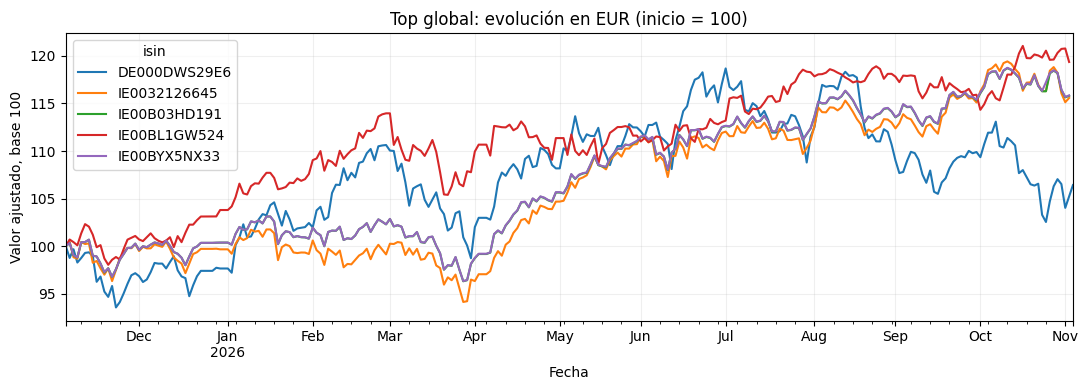

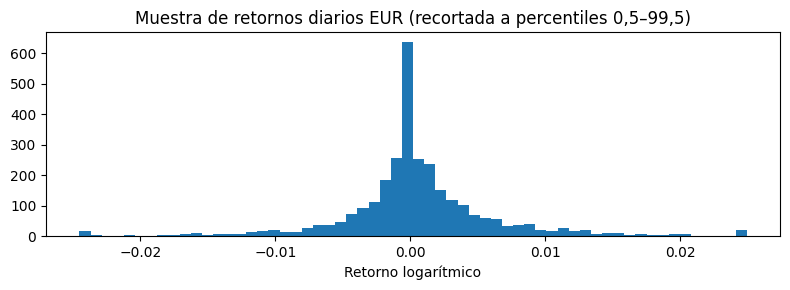

In [3]:
show_eda(ROOT, "mutual_fund", RESULT)

## 3. Qué significa «sector» en un fondo

Se usa la categoría publicada del fondo: renta variable global, bonos, tecnología, etc.
Un fondo diversificado no se fuerza a pertenecer a un solo sector corporativo.
Solo si falta esa clasificación se agrupan trayectorias mediante clustering (mínimo
4 activos y 60 observaciones comunes). El resultado se llama «grupo estadístico»,
sin atribuirle un sector económico inventado. Las categorías conocidas se conservan.


## 4. Top 5 global y por sector/categoría

Orden: **rentabilidad histórica anualizada (CAGR) en EUR**, de mayor a menor.
Justo a la derecha del CAGR se muestra la **rentabilidad de los últimos 12 meses**.
El criterio se aplica tanto al top global como al top por sector/categoría.

`CAGR = ((precio ajustado EUR final / inicial) ** (1 / años) - 1) * 100`

Se usa todo el histórico descargado desde el primer precio observado de cada ISIN
hasta el último, con años = días naturales / 365,25. Es una media compuesta, no una
media aritmética. Se muestran las fechas y los años porque los periodos pueden ser distintos;
el inicio configurado limita el histórico y no equivale necesariamente a toda la vida del fondo.

Se conservan los filtros existentes: un año completo, datos recientes y calidad del último año.
Los huecos del histórico completo se muestran en la tabla de limpieza; el CAGR usa los extremos
observados, sin extrapolar una fecha inicial anterior. Los activos excluidos siguen visibles en EDA.
Si hay menos de cinco activos elegibles se muestran los disponibles. Fondos y ETF se clasifican por separado.


In [4]:
show_rankings(RESULT)

### Top 5 global por rentabilidad histórica anualizada (CAGR) en EUR

| Puesto | ISIN | Nombre | Histórico anualizado (CAGR) | Últimos 12 meses | Desde | Hasta | Años |
| --- | --- | --- | ---: | ---: | --- | --- | ---: |
| 1 | IE00BL1GW524 | iShares UK Index Fund (IE) D Acc EUR | 14.44% | 19.36% | 2020-05-18 | 2026-11-03 | 6.46 |
| 2 | IE0032126645 | Vanguard U.S. 500 Stock Index EUR Acc | 14.22% | 15.58% | 2020-01-02 | 2026-11-03 | 6.84 |
| 3 | DE000DWS29E6 | DWS Smart Industrial Technologies LC | 13.08% | 6.42% | 2020-10-01 | 2026-11-04 | 6.09 |
| 4 | IE00BYX5NX33 | Fidelity MSCI World Index P EUR Acc | 12.61% | 15.85% | 2020-01-02 | 2026-11-03 | 6.84 |
| 5 | IE00B03HD191 | Vanguard Global Stock Index EUR Acc | 12.57% | 15.80% | 2020-01-02 | 2026-11-03 | 6.84 |

CAGR calculado desde el primer precio observado hasta el último del histórico descargado. Los periodos pueden diferir entre activos. A su derecha se muestra la rentabilidad de los últimos 12 meses. Los filtros de calidad se aplican al último año; consulta también los huecos de todo el histórico en la tabla de limpieza.

### Top 5 por sector o categoría

**Alternative Global Macro**

| Puesto | ISIN | Nombre | Histórico anualizado (CAGR) | Últimos 12 meses | Desde | Hasta | Años |
| --- | --- | --- | ---: | ---: | --- | --- | ---: |
| 1 | LU0115098948 | JPM Global Macro Opportunities D Acc EUR | -2.29% | -4.67% | 2022-03-07 | 2026-11-03 | 4.66 |

**Bond EMU Government**

| Puesto | ISIN | Nombre | Histórico anualizado (CAGR) | Últimos 12 meses | Desde | Hasta | Años |
| --- | --- | --- | ---: | ---: | --- | --- | ---: |
| 1 | IE0007472990 | Vanguard Euro Government Bond Index EUR Acc | -1.76% | -2.60% | 2020-01-02 | 2026-11-03 | 6.84 |
| 2 | IE00BD0NC037 | iShares Euro Govt Bd Idx (IE) D Acc EUR | -1.84% | -2.75% | 2020-01-02 | 2026-11-03 | 6.84 |
| 3 | IE00B1N7ZB00 | iShares Euro Govt Bd Idx (IE) Inst Dist EUR | -1.87% | -2.79% | 2020-01-02 | 2026-11-03 | 6.84 |
| 4 | IE0031080868 | iShares Euro Govt Bd Idx (IE) Inst Acc EUR | -1.87% | -2.78% | 2020-01-02 | 2026-11-03 | 6.84 |
| 5 | IE00BDRK7H99 | iShares Ultra Hi Qual Euro Govt Bd Idx D EUR Acc | -2.39% | -1.52% | 2020-01-02 | 2026-11-03 | 6.84 |

**Bond EMU Government Long Term**

| Puesto | ISIN | Nombre | Histórico anualizado (CAGR) | Últimos 12 meses | Desde | Hasta | Años |
| --- | --- | --- | ---: | ---: | --- | --- | ---: |
| 1 | IE00B246KL88 | Vanguard 20+ Year Euro Treasury Index EUR Acc | -9.11% | -9.58% | 2020-01-02 | 2026-11-03 | 6.84 |

... (27 outputs left out)

**Equity US**

| Puesto | ISIN | Nombre | Histórico anualizado (CAGR) | Últimos 12 meses | Desde | Hasta | Años |
| --- | --- | --- | ---: | ---: | --- | --- | ---: |
| 1 | IE0032126645 | Vanguard U.S. 500 Stock Index EUR Acc | 14.22% | 15.58% | 2020-01-02 | 2026-11-03 | 6.84 |
| 2 | IE00B1G3DH73 | Vanguard U.S. 500 Stock Index EUR Hedged Acc | 11.84% | 10.25% | 2020-01-02 | 2026-11-03 | 6.84 |

**Mixed Asset EUR Balanced - Global**

| Puesto | ISIN | Nombre | Histórico anualizado (CAGR) | Últimos 12 meses | Desde | Hasta | Años |
| --- | --- | --- | ---: | ---: | --- | --- | ---: |
| 1 | LU0093503737 | BGF ESG Multi-Asset Fund E2 EUR | 3.36% | 8.17% | 2022-03-07 | 2026-11-04 | 4.66 |

**Mixed Asset EUR Conservative - Global**

| Puesto | ISIN | Nombre | Histórico anualizado (CAGR) | Últimos 12 meses | Desde | Hasta | Años |
| --- | --- | --- | ---: | ---: | --- | --- | ---: |
| 1 | DE000DWS1UR7 | DWS CIO View Defensive EUR (Acc) | 2.56% | 1.30% | 2020-01-02 | 2026-11-04 | 6.84 |
| 2 | DE0005318406 | DWS ESG Stiftungsfonds EUR (Dist) | 1.81% | 1.63% | 2020-01-02 | 2026-11-04 | 6.84 |

**Money Market EUR**

| Puesto | ISIN | Nombre | Histórico anualizado (CAGR) | Últimos 12 meses | Desde | Hasta | Años |
| --- | --- | --- | ---: | ---: | --- | --- | ---: |
| 1 | IE0003323494 | FIL - The Euro Fund A Acc | 1.43% | 2.17% | 2020-01-02 | 2026-11-04 | 6.84 |